# LightGBM M2 on IEEE-CIS
This notebook adds LightGBM to M2 (periodic retraining) in `05_ieee_m0_m2.ipynb` Section 9, so all four families (LR, RF, CatBoost and LightGBM) have M0, M1 and M2 results on IEEE-CIS. The best family after M2 is the one that goes on to M3 and M4

Everything except the model is the same as notebook 05:
- **Data and evaluation**: the same loading code, the same `evaluate` function and the same seed

- **M2 setup**: the same functions (`fit_encodings`, `apply_encodings`, `retrain_scores`), copied from notebook 05 Section 9.1 => a 7-day label delay, and the frequency and `card1` statistic features are refitted at each retrain on all rows before the block (they do not use labels, so the delay does not apply to them)

- **Choosing the retraining settings**: the same simulation on the training days (days 81 to 109, retrain every 7 or 14 days, window of 28, 56 or all earlier days), and the best combination is kept for the validation rows

- **Validation runs**: static (trained once) vs M2 (retrained), each with the 7-day delay and with a 0-day delay as reference, and PR-AUC per validation week

- **LightGBM settings**: the M0 settings from `05b_ieee_lightgbm_m0_m1.ipynb` (300 trees, learning rate 0.05, 31 leaves, no class weights). M2 is built on M0 like the other families, since class weights lowered PR-AUC for every family including LightGBM

The scores of each run are saved in `data/interim/m2_scores_refit/` (the same folder as notebook 05), so a rerun loads the runs that already finished. The LightGBM runs have their own file names, so they never overwrite the other families

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import lightgbm as lgb
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)

pd.set_option("display.max_columns", 100)

SEED = 100   # same seed as notebook 05
PROCESSED_DIR = Path("../data/processed")

## 1. Load the Features
Same as notebook 05 Sections 2.1 and 2.2: only the training and validation rows are kept, categorical columns are pandas categories with `"missing"` as its own value, and the six code columns (`card1`, `card2`, `card3`, `card5`, `addr1`, `addr2`) are turned into text categories

In [2]:
features = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

feature_cols = feature_lists["ieee_feature_cols"]

# these columns are stored as numbers, but the numbers are codes with no order
CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]

cat_cols = [c for c in feature_cols if c in feature_lists["ieee_categorical_cols"] or c in CODE_AS_CATEGORY]
num_cols = [c for c in feature_cols if c not in cat_cols]

# keep only the needed columns, and only the training and validation rows
keep = feature_cols + ["isFraud", "ieee_split", "TransactionDT"]
features = features.loc[features["ieee_split"].isin(["train", "validation"]), keep]
features[num_cols] = features[num_cols].astype("float32")
for col in cat_cols:
    if col in CODE_AS_CATEGORY:
        # numbers to text codes e.g. 315.0 becomes "315" and a missing value becomes "missing"
        numbers = pd.to_numeric(features[col], errors="coerce")
        values = numbers.to_numpy(dtype="float64")
        rounded = np.round(values)
        whole = np.isfinite(values) & np.isclose(values, rounded)
        text = np.full(len(features), "missing", dtype=object)
        text[whole] = rounded[whole].astype("int64").astype(str)
        other = np.isfinite(values) & ~whole   # not a whole number => keep the value
        text[other] = numbers.to_numpy(dtype=object)[other]
        features[col] = pd.Series(text, index=features.index).astype("category")
    else:
        features[col] = features[col].astype("object").fillna("missing").astype(str).astype("category")

train = features[features["ieee_split"] == "train"]
val = features[features["ieee_split"] == "validation"]
del features

X_train, y_train = train[feature_cols], train["isFraud"]
X_val, y_val = val[feature_cols], val["isFraud"]
val_day = (val["TransactionDT"] // 86400).to_numpy()

print("training rows:", len(train), "| fraud rate:", round(y_train.mean() * 100, 2), "%")
print("validation rows:", len(val), "| fraud rate:", round(y_val.mean() * 100, 2), "% | days:", len(np.unique(val_day)))
print("features:", len(feature_cols), "| numeric:", len(num_cols), "| categorical (with the 6 code columns):", len(cat_cols))

training rows: 377945 | fraud rate: 3.41 %
validation rows: 94487 | fraud rate: 3.92 % | days: 33
features: 575 | numeric: 528 | categorical (with the 6 code columns): 47


## 2. Evaluation Metrics
The `evaluate` function from notebook 05 Section 3: PR-AUC (main metric), ROC-AUC, precision, recall and F1 at 0.5, precision@100 per day and the confusion matrix counts at 0.5

In [3]:
k = 100
metric_cols = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", f"precision@{k} per day"]


def evaluate(name, scores):
    predictions = (scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

    # precision@k per day: share of fraud among each day's k highest scores, averaged over the days
    daily = pd.DataFrame({"day": val_day, "y": y_val.to_numpy(), "score": scores})
    top_k = daily.sort_values("score", ascending=False, kind="stable").groupby("day").head(k)

    return {"model": name,
            "PR-AUC": average_precision_score(y_val, scores),
            "ROC-AUC": roc_auc_score(y_val, scores),
            "precision": precision_score(y_val, predictions, zero_division=0),
            "recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0),
            f"precision@{k} per day": top_k.groupby("day")["y"].mean().mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

## 3. LightGBM Model
The M0 LightGBM from notebook 05b: 300 trees, learning rate 0.05, 31 leaves, no depth limit and no class weights. LightGBM finds the categorical columns through the pandas category type and handles missing values itself, so it needs no preprocessing

In [4]:
models = {"LightGBM": lgb.LGBMClassifier(objective="binary", random_state=SEED, n_jobs=-1, verbosity=-1)}
base_settings = {"LightGBM": {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 31, "max_depth": -1}}

## 4. Retraining Setup
Copied from notebook 05 Section 9.1, so LightGBM is retrained in exactly the same way as the other families:
- **Label delay**: at the start of a block on day `d`, only transactions before day `d - 7` have labels, so the model trains on those only

- **Window**: the last `window` days of labelled transactions (28 or 56), or all of them (`"all"`)

- **Feature refit**: before each block, the frequency features and the `card1` statistics are refitted on all rows before the block start, and applied to the rows the model trains on and the rows it scores

- A **static** model is the same thing with a single block, so it is trained once and scores the whole period

`retrain_scores` also records how long each run takes, since the cost of retraining matters when choosing the family for M3 and M4

In [5]:
LABEL_DELAY_DAYS = 7

# scores of every retraining run are saved here (same folder as notebook 05), so a rerun can skip the runs that already finished
SCORES_DIR = Path("../data/interim/m2_scores_refit")
SCORES_DIR.mkdir(parents=True, exist_ok=True)

# training and validation rows in one frame, in time order, with the day of each row
day = np.concatenate([(train["TransactionDT"] // 86400).to_numpy(), val_day])
del train, val
X, y = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
del X_train, X_val
# the training rows come first in X
is_train = np.arange(len(X)) < len(y_train)
is_val = ~is_train
print("training rows:", is_train.sum(), ", days", day[is_train].min(), "to", day[is_train].max())
print("validation rows:", is_val.sum(), ", days", day[is_val].min(), "to", day[is_val].max())

training rows: 377945 , days 1 to 109
validation rows: 94487 , days 109 to 141


In [6]:
# the frequency and card1 statistic features from notebook 04, which are fitted there once on all training rows
FREQ_SOURCE_COLS = [c.removesuffix("_freq") for c in feature_cols if c.endswith("_freq")]
CARD1_STAT_SOURCE_COLS = ["TransactionAmt", "D1", "D10", "D15"]


# count of each value and the card1 statistics, learned from encode_rows only (no labels are used)
def fit_encodings(encode_rows):
    X_enc = X.loc[encode_rows, FREQ_SOURCE_COLS + CARD1_STAT_SOURCE_COLS]
    counts = {col: X_enc[col].value_counts() for col in FREQ_SOURCE_COLS}
    # float64 so the averages are the same as in notebook 04
    stats = {col: X_enc[col].astype("float64").groupby(X_enc["card1"], observed=True).agg(["mean", "std"]) for col in CARD1_STAT_SOURCE_COLS}
    return counts, stats


# replace the encoded columns of X_part (a value not in encode_rows gets a count of 0 and no statistics, as in notebook 04)
def apply_encodings(X_part, encodings):
    counts, stats = encodings
    for col in FREQ_SOURCE_COLS:
        X_part[f"{col}_freq"] = X_part[col].map(counts[col]).astype("float32").fillna(0)
    for col in CARD1_STAT_SOURCE_COLS:
        for stat in ["mean", "std"]:
            X_part[f"{col}_{stat}_by_card1"] = X_part["card1"].map(stats[col][stat]).astype("float32")
    return X_part

In [7]:
run_time = {}   # seconds per run (only for runs trained in this session)


def retrain_scores(family, run_name, labelled_rows, score_rows, first_day, last_day, frequency, window, delay):
    path = SCORES_DIR / f"{run_name}.pkl"
    if path.exists():
        return pd.read_pickle(path).loc[X.index[score_rows]]

    start = time.time()
    scores = pd.Series(np.nan, index=X.index[score_rows], dtype="float64")
    n_models = 0
    for block_start in range(first_day, last_day + 1, frequency):
        block = score_rows & (day >= block_start) & (day < block_start + frequency)
        if not block.any():
            continue

        # labelled rows: before the block start minus the label delay, inside the window
        label_end = block_start - delay
        fit_rows = labelled_rows & (day < label_end)
        if window != "all":
            fit_rows &= day >= label_end - window

        # encodings: refitted on all rows before the block start (they do not use labels, so the delay does not apply)
        encodings = fit_encodings(labelled_rows & (day < block_start))
        X_fit = apply_encodings(X[fit_rows].copy(), encodings)

        model = clone(models[family]).set_params(**base_settings[family])   # M0 settings, no class weights
        model.fit(X_fit, y[fit_rows])
        scores[X.index[block]] = model.predict_proba(apply_encodings(X[block].copy(), encodings))[:, 1]
        del model, X_fit
        n_models += 1

    scores.to_pickle(path)
    run_time[run_name] = time.time() - start
    print(f"{run_name}: {n_models} models ({run_time[run_name]:.0f}s)")
    return scores

## 5. Choosing the Retraining Settings on the Training Days
Same simulation as notebook 05 Section 9.2: retrain on the training rows only and score days 81 to 109 with the 7-day delay, for every combination of frequency (7, 14 days) and window (28, 56, all). The combination with the highest pooled PR-AUC is used on the validation rows, so the validation rows are not used for this choice

In [8]:
SIM_FIRST_DAY = 81
sim_rows = is_train & (day >= SIM_FIRST_DAY)
sim_last_day = int(day[is_train].max())
print(f"scored rows in the simulation: {sim_rows.sum()} (days {SIM_FIRST_DAY} to {sim_last_day}, fraud rate {y[sim_rows].mean() * 100:.2f}%)")

FREQUENCIES = [7, 14]
WINDOWS = [28, 56, "all"]

sim_results = []
for frequency in FREQUENCIES:
    for window in WINDOWS:
        run_name = f"sim_LightGBM_freq{frequency}_window{window}_delay{LABEL_DELAY_DAYS}"
        # only training rows can be used for training here (the validation rows come later)
        scores = retrain_scores("LightGBM", run_name, is_train, sim_rows, SIM_FIRST_DAY, sim_last_day, frequency, window, LABEL_DELAY_DAYS)
        sim_results.append({"frequency": frequency, "window": window, "PR-AUC": average_precision_score(y[sim_rows], scores)})

sim_table = pd.DataFrame(sim_results)
display(sim_table.pivot_table(index="frequency", columns="window", values="PR-AUC", sort=False).round(4))

best = sim_table.sort_values("PR-AUC", ascending=False).iloc[0]
best_frequency, best_window = int(best["frequency"]), best["window"]
print(f"LightGBM: retrain every {best_frequency} days on window {best_window} (simulation PR-AUC {best['PR-AUC']:.4f})")

scored rows in the simulation: 92519 (days 81 to 109, fraud rate 3.59%)


sim_LightGBM_freq7_window28_delay7: 5 models (32s)


sim_LightGBM_freq7_window56_delay7: 5 models (53s)


sim_LightGBM_freq7_windowall_delay7: 5 models (79s)


sim_LightGBM_freq14_window28_delay7: 3 models (19s)


sim_LightGBM_freq14_window56_delay7: 3 models (32s)


sim_LightGBM_freq14_windowall_delay7: 3 models (48s)


window,28,56,all
frequency,,,
7,0.5368,0.5417,0.5444
14,0.5243,0.5258,0.5326


LightGBM: retrain every 7 days on window all (simulation PR-AUC 0.5444)


**Takeaway: Retraining Settings**
- **Retraining every 7 days beats every 14 days for every window** (+0.012 to +0.016 PR-AUC) => labels that are a week fresher help, the same as for the other families in notebook 05

- **More history helps a little**: all earlier days (0.544) > last 56 days (0.542) > last 28 days (0.537). The gaps between windows are small (at most 0.008), **BUT** the order is the same for both frequencies

- Chosen setting: **every 7 days on all earlier days**, the same as RF and CatBoost in notebook 05 => the four families can be compared with the same retraining schedule (only LR uses the last 56 days)

- Cost: the six simulation runs took about 4.4 minutes in total (263s), while CatBoost every 7 days on all days took 3,031s on its own in notebook 05 (different machines, so only a rough comparison)

## 6. Static vs M2 on the Validation Rows
Same four runs as notebook 05 Section 9.3, with the frequency and window chosen above:
1. **Static, 7-day delay**: trained once on the labelled transactions before day 109 - 7 = 102

2. **M2, 7-day delay** (main result): retrained every `best_frequency` days, and each retrain can also use the validation transactions that are at least 7 days old

3. **Static, 0-day delay** and 4. **M2, 0-day delay** (reference): the same with each day's labels available once the day is over

In [9]:
VAL_FIRST_DAY, VAL_LAST_DAY = int(day[is_val].min()), int(day[is_val].max())
n_days = VAL_LAST_DAY - VAL_FIRST_DAY + 1

m2_scores = {}   # validation scores of the static and M2 runs
for delay in [LABEL_DELAY_DAYS, 0]:
    print(f"LightGBM, delay {delay}:")
    # static: one block covering the whole validation period
    m2_scores[f"static LightGBM, delay {delay}"] = retrain_scores(
        "LightGBM", f"val_static_LightGBM_window{best_window}_delay{delay}", is_train | is_val, is_val, VAL_FIRST_DAY, VAL_LAST_DAY, n_days, best_window, delay).to_numpy()
    m2_scores[f"M2 LightGBM, delay {delay}"] = retrain_scores(
        "LightGBM", f"val_m2_LightGBM_freq{best_frequency}_window{best_window}_delay{delay}", is_train | is_val, is_val, VAL_FIRST_DAY, VAL_LAST_DAY, best_frequency, best_window, delay).to_numpy()

LightGBM, delay 7:


val_static_LightGBM_windowall_delay7: 1 models (20s)


val_m2_LightGBM_freq7_windowall_delay7: 5 models (96s)
LightGBM, delay 0:


val_static_LightGBM_windowall_delay0: 1 models (19s)


val_m2_LightGBM_freq7_windowall_delay0: 5 models (104s)


## 7. Results
### 7.1 Static vs M2

In [10]:
m2_table = pd.DataFrame([evaluate(name, scores) for name, scores in m2_scores.items()]).set_index("model")
display(m2_table.round(4))

# change from static to M2 for each delay (M2 - static)
rows = []
for delay in [LABEL_DELAY_DAYS, 0]:
    static, m2 = m2_table.loc[f"static LightGBM, delay {delay}"], m2_table.loc[f"M2 LightGBM, delay {delay}"]
    rows.append({"delay": delay} | {metric: m2[metric] - static[metric] for metric in metric_cols})
print("change from static to M2 (M2 - static):")
display(pd.DataFrame(rows).set_index("delay").round(4))

if run_time:
    print("run time in this session (s):")
    display(pd.Series(run_time).round(0).to_frame("seconds"))

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
"static LightGBM, delay 7",0.5722,0.9038,0.8350,0.3715,0.5142,0.5824,1376,272,2328,90511
"M2 LightGBM, delay 7",0.6187,0.9229,0.8550,0.3979,0.5431,0.6130,1474,250,2230,90533
"static LightGBM, delay 0",0.5927,0.9131,0.8468,0.3909,0.5349,0.5891,1448,262,2256,90521
"M2 LightGBM, delay 0",0.6628,0.9328,0.8691,0.4463,0.5897,0.6494,1653,249,2051,90534


change from static to M2 (M2 - static):


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day
delay,,,,,,
7,0.0465,0.0191,0.0200,0.0265,0.0289,0.0306
0,0.0701,0.0197,0.0223,0.0553,0.0548,0.0603


run time in this session (s):


,seconds
sim_LightGBM_freq7_window28_delay7,32.0
sim_LightGBM_freq7_window56_delay7,53.0
sim_LightGBM_freq7_windowall_delay7,79.0
sim_LightGBM_freq14_window28_delay7,19.0
sim_LightGBM_freq14_window56_delay7,32.0
sim_LightGBM_freq14_windowall_delay7,48.0
val_static_LightGBM_windowall_delay7,20.0
val_m2_LightGBM_freq7_windowall_delay7,96.0
val_static_LightGBM_windowall_delay0,19.0
val_m2_LightGBM_freq7_windowall_delay0,104.0


### 7.2 PR-AUC per Validation Week
Same weeks as notebook 05 Section 9.4. The fraud rate differs between weeks, so only compare models within the same week

week,1,2,3,4,5
model,,,,,
"static LightGBM, delay 7",0.6391,0.5801,0.6180,0.5059,0.4020
"M2 LightGBM, delay 7",0.6391,0.6033,0.6637,0.6148,0.5109
"static LightGBM, delay 0",0.6663,0.6054,0.6269,0.5186,0.4287
"M2 LightGBM, delay 0",0.6663,0.6509,0.7068,0.6781,0.5764


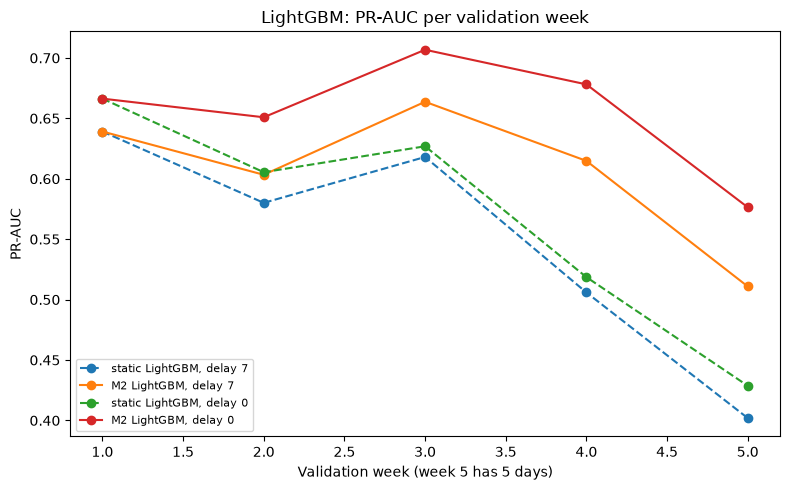

In [11]:
week = (val_day - VAL_FIRST_DAY) // 7
weekly = []
for name, scores in m2_scores.items():
    for w in np.unique(week):
        rows_w = week == w
        weekly.append({"model": name, "week": int(w) + 1, "PR-AUC": average_precision_score(y_val.to_numpy()[rows_w], scores[rows_w])})
weekly = pd.DataFrame(weekly)
display(weekly.pivot_table(index="model", columns="week", values="PR-AUC", sort=False).round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for name in m2_scores:
    data = weekly[weekly["model"] == name]
    ax.plot(data["week"], data["PR-AUC"], marker="o", linestyle="-" if name.startswith("M2") else "--", label=name)
ax.set_title("LightGBM: PR-AUC per validation week")
ax.set_xlabel("Validation week (week 5 has 5 days)")
ax.set_ylabel("PR-AUC")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 7.3 Comparison with the Other Families
The LR, RF and CatBoost rows are copied from notebook 05 (M0 from Section 4, static and M2 from Section 9.4, same validation rows and metrics). LightGBM M0 is from notebook 05b. The retraining settings of each family were chosen by its own simulation on the training days

Run times are not compared across notebooks, because they depend on the machine. For reference, in notebook 05 the M2 run with the 7-day delay took 213s for LR, 782s for RF and 4,005s for CatBoost

In [12]:
other_families = pd.DataFrame(
    [
        ["LR", "every 7 days, last 56 days", 0.5265, 0.5013, 0.5112, 0.5311],
        ["RF", "every 7 days, all days", 0.5591, 0.5458, 0.5624, 0.5820],
        ["CatBoost", "every 7 days, all days", 0.6255, 0.6008, 0.6534, 0.6920],
    ],
    columns=["family", "retraining", "M0", "static, delay 7", "M2, delay 7", "M2, delay 0"],
).set_index("family")

lightgbm_row = pd.DataFrame(
    [["LightGBM", f"every {best_frequency} days, " + ("all days" if best_window == "all" else f"last {best_window} days"), 0.5945,
      m2_table.loc[f"static LightGBM, delay {LABEL_DELAY_DAYS}", "PR-AUC"],
      m2_table.loc[f"M2 LightGBM, delay {LABEL_DELAY_DAYS}", "PR-AUC"],
      m2_table.loc["M2 LightGBM, delay 0", "PR-AUC"]]],
    columns=other_families.reset_index().columns,
).set_index("family")

family_table = pd.concat([other_families, lightgbm_row])
family_table["M2 - static"] = family_table["M2, delay 7"] - family_table["static, delay 7"]
print("PR-AUC on the validation rows:")
display(family_table.sort_values("M2, delay 7", ascending=False).round(4))

PR-AUC on the validation rows:


,retraining,M0,"static, delay 7","M2, delay 7","M2, delay 0",M2 - static
family,,,,,,
CatBoost,"every 7 days, all days",0.6255,0.6008,0.6534,0.6920,0.0526
LightGBM,"every 7 days, all days",0.5945,0.5722,0.6187,0.6628,0.0465
RF,"every 7 days, all days",0.5591,0.5458,0.5624,0.5820,0.0166
LR,"every 7 days, last 56 days",0.5265,0.5013,0.5112,0.5311,0.0099


## 8. Takeaways
- **M2 beats the static model**: with the 7-day delay, PR-AUC goes from 0.572 to 0.619 (+0.047). This is the second-largest gain after CatBoost (+0.053), well ahead of RF (+0.017) and LR (+0.010) => retraining helps the boosted trees the most

- **M2 LightGBM (0.619) also beats M0 LightGBM (0.595)**, which was trained once with no label delay

- **The gain comes from the later weeks**: week 1 is the same (same first model), then static LightGBM drops from 0.639 in week 1 to 0.402 in week 5, while M2 is still at 0.511 in week 5 => M2 handles the drift, as for the other families

- **The 7-day delay costs M2 0.044 PR-AUC** (0.663 with immediate labels vs 0.619), close to CatBoost (-0.039) => M3 can try to recover this with the unlabelled last 7 days

- **CatBoost is still the best family after M2**: 0.653 vs 0.619 for LightGBM (a gap of 0.035, well above the seed range in notebook 05 Section 5.6). The family ranking is the same as in M0 and M1: CatBoost > LightGBM > RF > LR

- **BUT LightGBM is much cheaper to retrain**: the M2 run with the 7-day delay took 96s here, vs 4,005s for CatBoost in notebook 05. The machines differ, so the exact ratio is not reliable, **BUT** the difference is far larger than any machine difference

- **For M3 and M4**: CatBoost has the best PR-AUC, so it is the natural choice. LightGBM is a reasonable alternative if M3 needs many more retrains (e.g. pseudo-labelling at every block), since it is second-best at a small fraction of the cost. Both still use default settings (LightGBM 300 trees and learning rate 0.05, CatBoost 500 trees and learning rate 0.1), so tuning in notebook 07 could change the gap